# Naïve Bayes Restaurant Review Sentiment Classification

In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

print("Libraries imported successfully!")

Libraries imported successfully!


## Load the dataset

In [3]:
df = pd.read_csv("output.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Display the first 10 records

In [4]:
df.head(10)

,Review,Liked
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,1
4,The selection on the menu was great and so were the prices.,1
5,Now I am getting angry and I want my damn pho.,0
6,Honeslty it didn't taste THAT fresh.),0
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,0
8,The fries were great too.,1
9,A great touch.,1


## Understand the dataset

### 1. Check the number of rows and columns

In [5]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1000, 2)


### 2. Check column names

In [6]:
print("Column Names:")
print(df.columns)

Column Names:
Index([' Review', 'Liked'], dtype='object')


In [7]:
# Remove leading and trailing spaces from column names

df.columns = df.columns.str.strip()

print("Updated Column Names:")
print(df.columns)

Updated Column Names:
Index(['Review', 'Liked'], dtype='object')


### 3. Check data types and non-null values

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Review  1000 non-null   object
 1   Liked   1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB


### 4. Display the last 5 records

In [9]:
df.tail()

,Review,Liked
995,I think food should have flavor and texture and both were lacking.,0
996,Appetite instantly gone.,0
997,Overall I was not impressed and would not go back.,0
998,"The whole experience was underwhelming, and I think we'll just go to Ninja Sushi next time.",0
999,"Then, as if I hadn't wasted enough of my life there, they poured salt in the wound by drawing out the time it took to bring the check.",0


### 5. Statistical summary

In [10]:
df.describe(include='all')

,Review,Liked
count,1000,1000.00000
unique,996,NaN
top,I won't be back.,NaN
freq,2,NaN
mean,NaN,0.50000
std,NaN,0.50025
min,NaN,0.00000
25%,NaN,0.00000
50%,NaN,0.50000
75%,NaN,1.00000


Column	- Meaning

Review	- Restaurant review written by a customer (input feature)

Liked	- Sentiment label (target variable)

1	- Positive review

0	- Negative review



Some reviews contain words such as "not good", "not tasty", and "didn't taste". We must preserve these negative expressions during text preprocessing because they are important for sentiment classification.

## Exploratory Data Analysis (EDA) 

### 1. Check positive and negative reviews

In [11]:
print("Sentiment Distribution:")
print(df['Liked'].value_counts())

Sentiment Distribution:
Liked
1    500
0    500
Name: count, dtype: int64


In [12]:
print("\nSentiment Percentage:")
print(df['Liked'].value_counts(normalize=True) * 100)


Sentiment Percentage:
Liked
1    50.0
0    50.0
Name: proportion, dtype: float64


### 2. Check missing values

In [13]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Review    0
Liked     0
dtype: int64


### 3. Check duplicate records

In [14]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 4


### 4. Analyse review length

In [15]:
df['Review_Length'] = df['Review'].apply(len)

print(df['Review_Length'].describe())

count    1000.000000
mean       58.315000
std        32.360052
min        11.000000
25%        33.000000
50%        51.000000
75%        80.000000
max       149.000000
Name: Review_Length, dtype: float64


### 5. Visualise positive and negative reviews

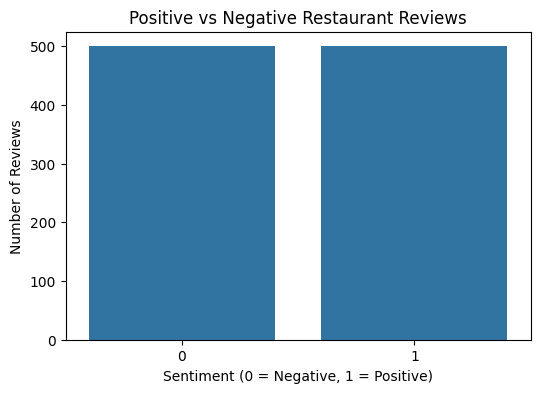

In [16]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Liked')

plt.title('Positive vs Negative Restaurant Reviews')
plt.xlabel('Sentiment (0 = Negative, 1 = Positive)')
plt.ylabel('Number of Reviews')

plt.show()

### 6. Review length distribution

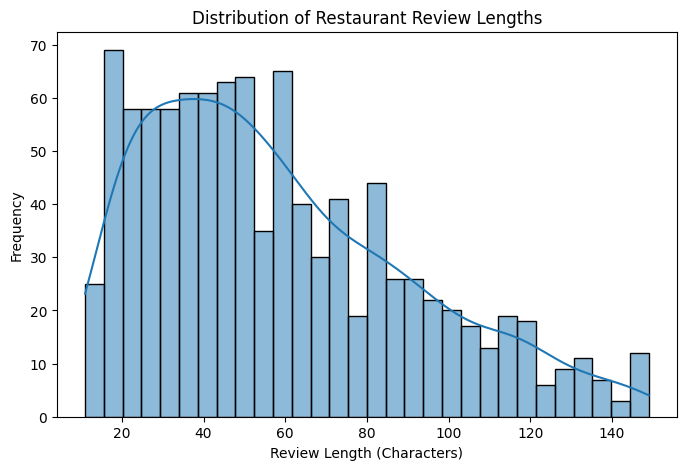

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Review_Length', bins=30, kde=True)

plt.title('Distribution of Restaurant Review Lengths')
plt.xlabel('Review Length (Characters)')
plt.ylabel('Frequency')

plt.show()

## Remove duplicate records

In [18]:
# Remove duplicate records

print("Shape before removing duplicates:", df.shape)

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

Shape before removing duplicates: (1000, 3)
Shape after removing duplicates: (996, 3)
Remaining duplicates: 0


The third column is Review_Length, which we created during EDA.

Why remove duplicates? Exact duplicate records can give repeated examples extra influence during model training. Removing them avoids that repetition.

## Prepare for text preprocessing

Before cleaning text, let's inspect a few original reviews.

In [19]:
for i in range(10):
    print(f"Original Review {i+1}: {df['Review'].iloc[i]}")
    print("-" * 70)

Original Review 1: Wow... Loved this place.
----------------------------------------------------------------------
Original Review 2: Crust is not good.
----------------------------------------------------------------------
Original Review 3: Not tasty and the texture was just nasty.
----------------------------------------------------------------------
Original Review 4: Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.
----------------------------------------------------------------------
Original Review 5: The selection on the menu was great and so were the prices.
----------------------------------------------------------------------
Original Review 6: Now I am getting angry and I want my damn pho.
----------------------------------------------------------------------
Original Review 7: Honeslty it didn't taste THAT fresh.)
----------------------------------------------------------------------
Original Review 8: The potatoes were like rubber an

## Text preprocessing
Now we'll clean the restaurant reviews so that the Naïve Bayes algorithm can learn meaningful words.

We'll perform these operations:
1. Convert text to lowercase.
2. Remove punctuation.
3. Remove unnecessary numbers.
4. Remove special characters.
5. Remove extra spaces.
6. Remove stopwords while preserving negative words.
7. Apply stemming.

Important: We will preserve words such as not, no, and never, because they can change the sentiment of a review.

### 1.import NLTK

In [20]:
import nltk

nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\bhuva\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\bhuva\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\bhuva\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

### 2 Import preprocessing tools

In [21]:
import re
import string

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

stop_words = set(stopwords.words('english'))

# Preserve important negative words
stop_words = stop_words - {'not', 'no', 'nor'}

stemmer = PorterStemmer()

print("Text preprocessing tools imported successfully!")

Text preprocessing tools imported successfully!


### 3 Create the text cleaning function

In [22]:
def preprocess_text(text):

    text = text.lower()

    # Expand common negative contractions
    text = re.sub(r"\bdidn't\b", "did not", text)
    text = re.sub(r"\bwasn't\b", "was not", text)
    text = re.sub(r"\bisn't\b", "is not", text)
    text = re.sub(r"\baren't\b", "are not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwouldn't\b", "would not", text)
    text = re.sub(r"\bcouldn't\b", "could not", text)
    text = re.sub(r"\bshouldn't\b", "should not", text)

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    words = text.split()

    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)


# Apply updated preprocessing
df['Cleaned_Review'] = df['Review'].apply(preprocess_text)

df[['Review', 'Cleaned_Review']].head(10)

,Review,Cleaned_Review
0,Wow... Loved this place.,wow love place
1,Crust is not good.,crust not good
2,Not tasty and the texture was just nasty.,not tasti textur nasti
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stop late may bank holiday rick steve recommend love
4,The selection on the menu was great and so were the prices.,select menu great price
5,Now I am getting angry and I want my damn pho.,get angri want damn pho
6,Honeslty it didn't taste THAT fresh.),honeslti not tast fresh
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,potato like rubber could tell made ahead time kept warmer
8,The fries were great too.,fri great
9,A great touch.,great touch


### 4 Apply preprocessing

In [23]:
print("Original:", df['Review'].iloc[6])
print("Cleaned :", df['Cleaned_Review'].iloc[6])

Original: Honeslty it didn't taste THAT fresh.)
Cleaned : honeslti not tast fresh


In [24]:
df['Cleaned_Review'] = df['Review'].apply(preprocess_text)

df[['Review', 'Cleaned_Review', 'Liked']].head(10)

,Review,Cleaned_Review,Liked
0,Wow... Loved this place.,wow love place,1
1,Crust is not good.,crust not good,0
2,Not tasty and the texture was just nasty.,not tasti textur nasti,0
3,Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.,stop late may bank holiday rick steve recommend love,1
4,The selection on the menu was great and so were the prices.,select menu great price,1
5,Now I am getting angry and I want my damn pho.,get angri want damn pho,0
6,Honeslty it didn't taste THAT fresh.),honeslti not tast fresh,0
7,The potatoes were like rubber and you could tell they had been made up ahead of time being kept under a warmer.,potato like rubber could tell made ahead time kept warmer,0
8,The fries were great too.,fri great,1
9,A great touch.,great touch,1


### 5 Compare original and cleaned reviews

For example:
- Original: Crust is not good.
- Cleaned: crust not good

Notice that not remains in the cleaned review.

In [25]:
for i in range(10):
    print("Original:", df['Review'].iloc[i])
    print("Cleaned :", df['Cleaned_Review'].iloc[i])
    print("-" * 70)

Original: Wow... Loved this place.
Cleaned : wow love place
----------------------------------------------------------------------
Original: Crust is not good.
Cleaned : crust not good
----------------------------------------------------------------------
Original: Not tasty and the texture was just nasty.
Cleaned : not tasti textur nasti
----------------------------------------------------------------------
Original: Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.
Cleaned : stop late may bank holiday rick steve recommend love
----------------------------------------------------------------------
Original: The selection on the menu was great and so were the prices.
Cleaned : select menu great price
----------------------------------------------------------------------
Original: Now I am getting angry and I want my damn pho.
Cleaned : get angri want damn pho
----------------------------------------------------------------------
Original: Honeslty 

## Separate input and target variables

In [26]:
X = df['Cleaned_Review']
y = df['Liked']

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (996,)
Target shape: (996,)


## Train-test split
Now we divide the dataset into two parts:
- 80% training data: Used to train the model.
- 20% testing data: Used to evaluate the model on unseen reviews.
  
We'll use stratify=y to preserve the equal positive and negative class distribution in both sets.

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (796,)
Testing data shape: (200,)


In [28]:
print("\nTraining target distribution:")
print(y_train.value_counts())


Training target distribution:
Liked
1    399
0    397
Name: count, dtype: int64


In [29]:
print("\nTesting target distribution:")
print(y_test.value_counts())


Testing target distribution:
Liked
1    100
0    100
Name: count, dtype: int64


## Import feature extraction techniques
Computers cannot directly understand text. We need to convert reviews into numerical features.

We'll compare two techniques:
1. CountVectorizer: Counts how often words appear.
2. TfidfVectorizer: Assigns importance to words based on their frequency across reviews.

In [30]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

print("CountVectorizer and TfidfVectorizer imported successfully!")

CountVectorizer and TfidfVectorizer imported successfully!


## Model 1: Multinomial Naïve Bayes + CountVectorizer

- CountVectorizer: Converts each review into a numerical representation based on word counts.



- Multinomial Naïve Bayes: Uses word frequencies to estimate whether a review is positive or negative.

### 1 Convert text into numerical features

In [31]:
from sklearn.feature_extraction.text import CountVectorizer

# Create CountVectorizer
cv = CountVectorizer()

# Fit on training data and transform
X_train_cv = cv.fit_transform(X_train)

# Transform testing data
X_test_cv = cv.transform(X_test)

print("Training feature matrix shape:", X_train_cv.shape)
print("Testing feature matrix shape:", X_test_cv.shape)

Training feature matrix shape: (796, 1392)
Testing feature matrix shape: (200, 1392)


Why do we use fit_transform() on training data and only transform() on testing data?

The vectorizer learns the vocabulary from training reviews. The test data must use that same vocabulary to avoid data leakage.

### 2 Train Multinomial Naïve Bayes

In [32]:
from sklearn.naive_bayes import MultinomialNB

# Create model
mnb_cv = MultinomialNB()

# Train model
mnb_cv.fit(X_train_cv, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


### 3 Make predictions

In [33]:
y_pred_cv = mnb_cv.predict(X_test_cv)

print("First 20 Actual Values:")
print(y_test.iloc[:20].values)

First 20 Actual Values:
[1 0 0 0 1 1 1 1 0 0 1 1 1 0 0 0 1 0 1 0]


In [34]:
print("\nFirst 20 Predicted Values:")
print(y_pred_cv[:20])


First 20 Predicted Values:
[1 0 1 1 1 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0]


### 4 Evaluate the model

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_cv))
print("Precision:", precision_score(y_test, y_pred_cv))
print("Recall:", recall_score(y_test, y_pred_cv))
print("F1 Score:", f1_score(y_test, y_pred_cv))

Accuracy: 0.81
Precision: 0.7980769230769231
Recall: 0.83
F1 Score: 0.8137254901960784


In [36]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_cv))


Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.79      0.81       100
           1       0.80      0.83      0.81       100

    accuracy                           0.81       200
   macro avg       0.81      0.81      0.81       200
weighted avg       0.81      0.81      0.81       200



In [37]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_cv))


Confusion Matrix:
[[79 21]
 [17 83]]


### 5 Visualise the confusion matrix

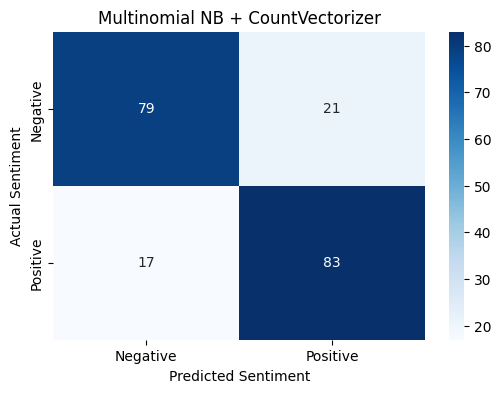

In [38]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, y_pred_cv),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Multinomial NB + CountVectorizer')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

- 79 negative reviews were correctly classified.
- 83 positive reviews were correctly classified.
- 21 negative reviews were incorrectly predicted as positive.
- 17 positive reviews were incorrectly predicted as negative.
Therefore, 162 out of 200 reviews were classified correctly.

## Model 2: Multinomial Naïve Bayes + TF-IDF

Now we'll use TF-IDF instead of CountVectorizer.

What is TF-IDF?

TF-IDF stands for Term Frequency–Inverse Document Frequency. It gives importance to words based on how frequently they occur in a review and how common they are across all reviews.

For example, a common word appearing in nearly every review may receive less importance than a distinctive word.

### 1 Convert text using TF-IDF

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer()

# Fit on training data and transform
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data
X_test_tfidf = tfidf.transform(X_test)

print("Training feature matrix shape:", X_train_tfidf.shape)
print("Testing feature matrix shape:", X_test_tfidf.shape)

Training feature matrix shape: (796, 1392)
Testing feature matrix shape: (200, 1392)


### 2 Train Multinomial Naïve Bayes

In [40]:
# Create model
mnb_tfidf = MultinomialNB()

# Train model
mnb_tfidf.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes with TF-IDF trained successfully!")

Multinomial Naive Bayes with TF-IDF trained successfully!


### 3 Make predictions

In [41]:
y_pred_tfidf = mnb_tfidf.predict(X_test_tfidf)

print("First 20 Actual Values:")
print(y_test.iloc[:20].values)

print("\nFirst 20 Predicted Values:")
print(y_pred_tfidf[:20])

First 20 Actual Values:
[1 0 0 0 1 1 1 1 0 0 1 1 1 0 0 0 1 0 1 0]

First 20 Predicted Values:
[1 0 1 1 1 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0]


### 4 Evaluate the model

In [42]:
print("Accuracy:", accuracy_score(y_test, y_pred_tfidf))
print("Precision:", precision_score(y_test, y_pred_tfidf))
print("Recall:", recall_score(y_test, y_pred_tfidf))
print("F1 Score:", f1_score(y_test, y_pred_tfidf))

Accuracy: 0.79
Precision: 0.7636363636363637
Recall: 0.84
F1 Score: 0.8


In [43]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tfidf))


Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.74      0.78       100
           1       0.76      0.84      0.80       100

    accuracy                           0.79       200
   macro avg       0.79      0.79      0.79       200
weighted avg       0.79      0.79      0.79       200



In [44]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tfidf))


Confusion Matrix:
[[74 26]
 [16 84]]


### 5 Visualise confusion matrix

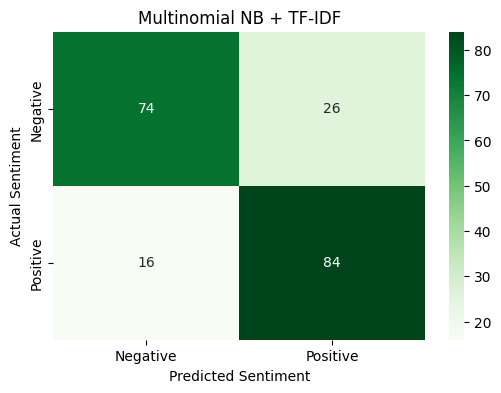

In [45]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, y_pred_tfidf),
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Multinomial NB + TF-IDF')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

- 74 negative reviews correctly classified.



- 84 positive reviews correctly classified.



- 26 negative reviews incorrectly predicted as positive.



- 16 positive reviews incorrectly predicted as negative.

Compare Model 1 and Model 2

Metric -	Model 1: Count -	Model 2: TF-IDF

Accuracy - 	81%	- 79%

Precision -	79.81% -	76.36%

Recall -	83% - 	84%

F1-score -	81.37% -	80%

Observation: Model 1 currently performs better in accuracy, precision and F1-score. Model 2 has slightly higher recall.

We should wait until Model 3 before selecting the final model.

## Model 3: Bernoulli Naïve Bayes + Binary Features

What is Bernoulli Naïve Bayes?

Unlike Multinomial Naïve Bayes, which considers word frequencies, Bernoulli Naïve Bayes focuses on whether a word is present or absent in a review.

For example:

Word	- Review: "food not good"

food	- 1

not	- 1

good	- 1

great	- 0

tasty	- 0

Here, 1 means the word is present and 0 means it is absent.

### 1 Convert reviews into binary features

In [46]:
from sklearn.feature_extraction.text import CountVectorizer

# Create binary CountVectorizer
binary_vectorizer = CountVectorizer(binary=True)

# Fit and transform training data
X_train_binary = binary_vectorizer.fit_transform(X_train)

# Transform testing data
X_test_binary = binary_vectorizer.transform(X_test)

print("Training feature matrix shape:", X_train_binary.shape)
print("Testing feature matrix shape:", X_test_binary.shape)

Training feature matrix shape: (796, 1392)
Testing feature matrix shape: (200, 1392)


### 2 Train Bernoulli Naïve Bayes

In [47]:
from sklearn.naive_bayes import BernoulliNB

# Create Bernoulli Naive Bayes model
bnb = BernoulliNB()

# Train model
bnb.fit(X_train_binary, y_train)

print("Bernoulli Naive Bayes model trained successfully!")

Bernoulli Naive Bayes model trained successfully!


### 3 Make predictions

In [48]:
y_pred_binary = bnb.predict(X_test_binary)

print("First 20 Actual Values:")
print(y_test.iloc[:20].values)

print("\nFirst 20 Predicted Values:")
print(y_pred_binary[:20])

First 20 Actual Values:
[1 0 0 0 1 1 1 1 0 0 1 1 1 0 0 0 1 0 1 0]

First 20 Predicted Values:
[1 0 1 1 1 1 1 0 0 0 1 0 1 0 1 0 1 0 0 0]


### 4 Evaluate the model

In [49]:
print("Accuracy:", accuracy_score(y_test, y_pred_binary))
print("Precision:", precision_score(y_test, y_pred_binary))
print("Recall:", recall_score(y_test, y_pred_binary))
print("F1 Score:", f1_score(y_test, y_pred_binary))

Accuracy: 0.795
Precision: 0.7757009345794392
Recall: 0.83
F1 Score: 0.8019323671497585


In [50]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_binary))


Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.76      0.79       100
           1       0.78      0.83      0.80       100

    accuracy                           0.80       200
   macro avg       0.80      0.79      0.79       200
weighted avg       0.80      0.80      0.79       200



In [51]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_binary))


Confusion Matrix:
[[76 24]
 [17 83]]


### 5 Visualise the confusion matrix

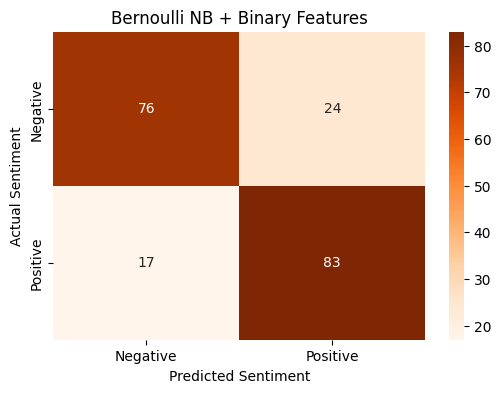

In [52]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, y_pred_binary),
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Bernoulli NB + Binary Features')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

## Compare all three models

In [53]:
# Create model comparison

results = {
    'Model': [
        'Multinomial NB + CountVectorizer',
        'Multinomial NB + TF-IDF',
        'Bernoulli NB + Binary Features'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_cv),
        accuracy_score(y_test, y_pred_tfidf),
        accuracy_score(y_test, y_pred_binary)
    ],

    'Precision': [
        precision_score(y_test, y_pred_cv),
        precision_score(y_test, y_pred_tfidf),
        precision_score(y_test, y_pred_binary)
    ],

    'Recall': [
        recall_score(y_test, y_pred_cv),
        recall_score(y_test, y_pred_tfidf),
        recall_score(y_test, y_pred_binary)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_cv),
        f1_score(y_test, y_pred_tfidf),
        f1_score(y_test, y_pred_binary)
    ]
}

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial NB + CountVectorizer,0.810,0.798077,0.83,0.813725
1,Multinomial NB + TF-IDF,0.790,0.763636,0.84,0.800000
2,Bernoulli NB + Binary Features,0.795,0.775701,0.83,0.801932


## Visualise model comparison

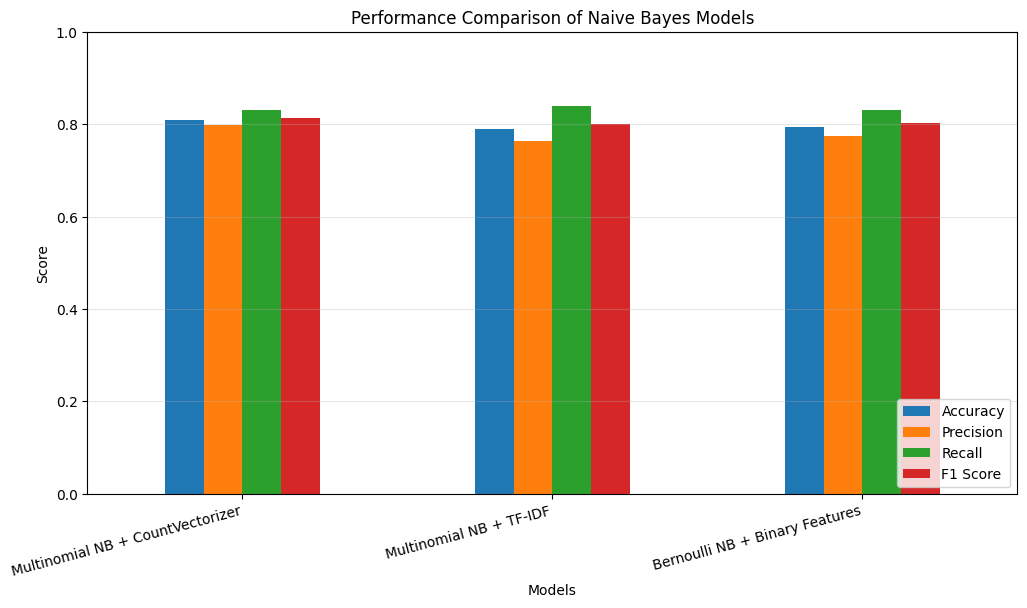

In [54]:
comparison_df.set_index('Model').plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Performance Comparison of Naive Bayes Models')
plt.ylabel('Score')
plt.xlabel('Models')
plt.ylim(0, 1)
plt.xticks(rotation=15, ha='right')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)

plt.show()

## Identify the best model

In [55]:
best_model_row = comparison_df.loc[
    comparison_df['Accuracy'].idxmax()
]

print("Best Model:")
print(best_model_row['Model'])

print("\nBest Accuracy:")
print(best_model_row['Accuracy'])

print("\nBest F1 Score:")
print(best_model_row['F1 Score'])

Best Model:
Multinomial NB + CountVectorizer

Best Accuracy:
0.81

Best F1 Score:
0.8137254901960784


Based on your current results, Model 1 (CountVectorizer + MultinomialNB) has the highest accuracy and F1-score.

However, we will confirm this using the comparison table.

## Predict sentiment for five new reviews

Once the comparison is complete, we'll test the best model on new restaurant reviews that were not part of the original dataset.

For now, use Model 1:

In [56]:
# Five new restaurant reviews

new_reviews = [
    "The food was absolutely delicious and the service was excellent.",
    "The food was terrible and the staff was very rude.",
    "I loved the atmosphere and the food was amazing.",
    "The restaurant was dirty and the food was not tasty.",
    "Great experience, friendly staff and wonderful food."
]

# Apply the same preprocessing
cleaned_reviews = [preprocess_text(review) for review in new_reviews]

# Convert text using the already fitted CountVectorizer
new_reviews_vectorized = cv.transform(cleaned_reviews)

# Predict sentiment
new_predictions = mnb_cv.predict(new_reviews_vectorized)

# Display results
for review, prediction in zip(new_reviews, new_predictions):

    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 80)

Review: The food was absolutely delicious and the service was excellent.
Predicted Sentiment: Positive
--------------------------------------------------------------------------------
Review: The food was terrible and the staff was very rude.
Predicted Sentiment: Negative
--------------------------------------------------------------------------------
Review: I loved the atmosphere and the food was amazing.
Predicted Sentiment: Positive
--------------------------------------------------------------------------------
Review: The restaurant was dirty and the food was not tasty.
Predicted Sentiment: Negative
--------------------------------------------------------------------------------
Review: Great experience, friendly staff and wonderful food.
Predicted Sentiment: Positive
--------------------------------------------------------------------------------


Important: We use the same preprocessing function and fitted vectorizer used during training. We must not fit a new vectorizer on these reviews.

## Save the best model and vectorizer

Now we'll save your selected model so you can reuse it without training it again every time.

We'll save two files:
- sentiment_model.pkl – trained Multinomial Naïve Bayes model.
- count_vectorizer.pkl – fitted CountVectorizer.

### 1 import Joblib

In [57]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: C:\Users\bhuva\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [58]:
import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


### 2 Save the model and vectorizer

In [59]:
# Save trained model
joblib.dump(mnb_cv, 'sentiment_model.pkl')

# Save fitted vectorizer
joblib.dump(cv, 'count_vectorizer.pkl')

print("Model saved successfully!")
print("Vectorizer saved successfully!")

Model saved successfully!
Vectorizer saved successfully!


### 3 Verify saved files

In [60]:
import os

print("Model exists:", os.path.exists('sentiment_model.pkl'))
print("Vectorizer exists:", os.path.exists('count_vectorizer.pkl'))

Model exists: True
Vectorizer exists: True


### 4 Test loading the saved model

In [61]:
# Load saved model and vectorizer
loaded_model = joblib.load('sentiment_model.pkl')
loaded_vectorizer = joblib.load('count_vectorizer.pkl')

# Test with a new review
test_review = ["The food was amazing and the service was excellent."]

# Apply the same preprocessing
cleaned_review = [preprocess_text(review) for review in test_review]

# Convert text into numerical features
review_features = loaded_vectorizer.transform(cleaned_review)

# Predict sentiment
prediction = loaded_model.predict(review_features)

print("Review:", test_review[0])
print("Predicted Sentiment:", "Positive" if prediction[0] == 1 else "Negative")

Review: The food was amazing and the service was excellent.
Predicted Sentiment: Positive


In [66]:
# Assignment-specific sample reviews
sample_reviews = [
    "The food was fantastic and the service was excellent.",
    "Worst service ever. The food was terrible.",
    "The restaurant has a beautiful ambience.",
    "The experience was average and nothing special."
]

# Preprocess the reviews
cleaned_reviews = [preprocess_text(review) for review in sample_reviews]

# Convert reviews into numerical features
sample_features = cv.transform(cleaned_reviews)

# Predict sentiment
sample_predictions = mnb_cv.predict(sample_features)

# Predict probabilities
sample_probabilities = mnb_cv.predict_proba(sample_features)

# Display results
for i, review in enumerate(sample_reviews):

    sentiment = "Positive" if sample_predictions[i] == 1 else "Negative"

    negative_probability = sample_probabilities[i][0] * 100
    positive_probability = sample_probabilities[i][1] * 100

    print("-" * 80)
    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print(f"Negative Probability: {negative_probability:.2f}%")
    print(f"Positive Probability: {positive_probability:.2f}%")

--------------------------------------------------------------------------------
Review: The food was fantastic and the service was excellent.
Predicted Sentiment: Positive
Negative Probability: 0.77%
Positive Probability: 99.23%
--------------------------------------------------------------------------------
Review: Worst service ever. The food was terrible.
Predicted Sentiment: Negative
Negative Probability: 98.61%
Positive Probability: 1.39%
--------------------------------------------------------------------------------
Review: The restaurant has a beautiful ambience.
Predicted Sentiment: Positive
Negative Probability: 3.56%
Positive Probability: 96.44%
--------------------------------------------------------------------------------
Review: The experience was average and nothing special.
Predicted Sentiment: Negative
Negative Probability: 87.61%
Positive Probability: 12.39%


In [63]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.3
[notice] To update, run: C:\Users\bhuva\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [64]:
import streamlit as st
print("Streamlit version:", st.__version__)

Streamlit version: 1.53.1


In [65]:
import sys
!{sys.executable} -m streamlit run app.py

^C
